# Etapa 1 — Diagnóstico e preparação: risco de incêndio por município e dia

**O problema.** Brigadas e defesa civil precisam decidir, todo dia, onde deixar equipes de prontidão. O
modelo deste projeto vai prever o **nível de risco de incêndio (Baixo, Médio ou Alto) para cada município
e dia**, usando só o que se sabe até a véspera.

**Três palavras que aparecem o tempo todo:**
- **Alvo:** o que o modelo tenta prever. Aqui, o nível de risco do dia.
- **Município-dia:** um município num dia (por exemplo, Altamira em 19 de abril de 2024). Cada linha da base
  do modelo é um município-dia.
- **Feature:** cada coluna que o modelo usa para prever o alvo, como "quantos focos houve ontem".

**As bases** (Base dos Dados, fornecidas pela TripleTen): focos de queimada do INPE (Instituto Nacional de
Pesquisas Espaciais), uso do solo do MapBiomas (projeto que mapeia a cobertura do solo do Brasil por
satélite) e medições meteorológicas do INMET (Instituto Nacional de Meteorologia), por estação. A base do
INMET fornecida se chama BDMEP. Como o BDMEP fornecido só cobre 2025, o
clima de 2024 foi completado com os **dados históricos anuais do INMET** (a mesma fonte, no portal oficial),
e as coordenadas das sedes dos municípios vieram de uma base pública (seção 1).

**O ponto de partida: o dado que falta.** Na Segunda Guerra, o estatístico Abraham Wald analisou os
aviões que voltavam de combate cheios de buracos nas asas. A conclusão certa não era blindar as asas, e
sim onde *não* havia buracos: os aviões atingidos ali não voltaram para entrar na estatística. A base de
queimadas tem o mesmo **viés de sobrevivência**: ela só registra onde o satélite viu fogo. Os municípios
e dias sem fogo, que são exatamente os de risco baixo, não aparecem. Este notebook mostra esse viés com
números e monta uma base que inclui esses dias.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# acha a pasta do projeto (a que tem src/consolidar_base.py), de onde quer que o notebook seja aberto
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'consolidar_base.py').exists())
sys.path.insert(0, str(RAIZ / 'src'))
import consolidar_base as cb

con = cb.conectar()
q = lambda sql: con.sql(sql).df()

AZUL, CINZA, LARANJA, VERMELHO = '#2f6fdb', '#9aa5b1', '#e8a33d', '#c0392b'
CORES_RISCO = {'Baixo': CINZA, 'Médio': LARANJA, 'Alto': VERMELHO}

## 1. As bases brutas

In [2]:
resumo = q('''
    SELECT 'queimadas' AS base, count(*) AS linhas, min(CAST(data_hora AS DATE)) AS inicio, max(CAST(data_hora AS DATE)) AS fim FROM queimadas
    UNION ALL SELECT 'bdmep', count(*), min(data), max(data) FROM bdmep
    UNION ALL SELECT 'mapbiomas', count(*), make_date(min(ano), 1, 1), make_date(max(ano), 12, 31) FROM mapbiomas
    UNION ALL SELECT 'estacoes (cadastro)', count(*), NULL, NULL FROM estacoes
    UNION ALL SELECT 'inmet_2024 (complemento)', count(*), min(CAST(data AS DATE)), max(CAST(data AS DATE)) FROM inmet_2024
    UNION ALL SELECT 'municipios (coordenadas)', count(*), NULL, NULL FROM municipios
''')
resumo

,base,linhas,inicio,fim
0,queimadas,8226944,2024-01-01,2025-02-12
1,bdmep,4891176,2025-01-01,2025-06-30
2,mapbiomas,2286656,1985-01-01,2021-12-31
3,estacoes (cadastro),612,NaT,NaT
4,inmet_2024 (complemento),4962960,2024-01-01,2024-12-31
5,municipios (coordenadas),5571,NaT,NaT


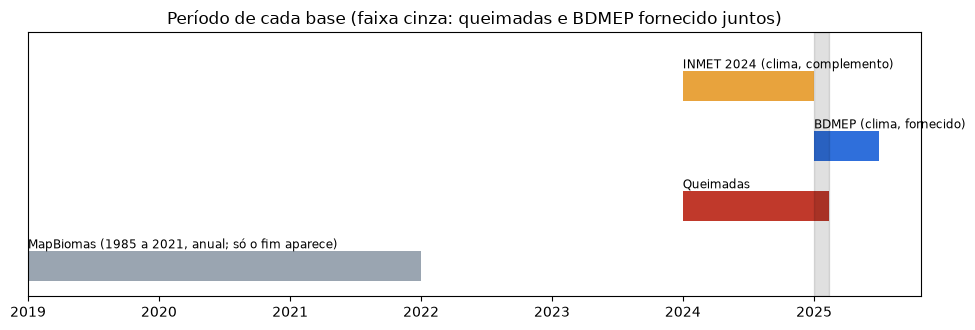

Dias em que queimadas e BDMEP coexistem: 43


In [3]:
fig, eixo = plt.subplots(figsize=(10, 3.4))
periodos = [('MapBiomas (1985 a 2021, anual; só o fim aparece)', '2019-01-01', '2021-12-31', CINZA),
            ('Queimadas', '2024-01-01', '2025-02-12', VERMELHO),
            ('BDMEP (clima, fornecido)', '2025-01-01', '2025-06-30', AZUL),
            ('INMET 2024 (clima, complemento)', '2024-01-01', '2024-12-31', LARANJA)]
for i, (nome, ini, fim, cor) in enumerate(periodos):
    ini, fim = pd.Timestamp(ini), pd.Timestamp(fim)
    eixo.barh(i, (fim - ini).days, left=ini, color=cor, height=0.5)
    eixo.text(ini, i + 0.3, nome, fontsize=8.5)
eixo.axvspan(pd.Timestamp('2025-01-01'), pd.Timestamp('2025-02-12'), color='black', alpha=0.12)
eixo.set_yticks([])
eixo.set_ylim(-0.5, len(periodos) - 0.1)
eixo.set_title('Período de cada base (faixa cinza: queimadas e BDMEP fornecido juntos)')
plt.tight_layout()
plt.show()

comum = q('''SELECT count(DISTINCT data) AS dias FROM bdmep
             WHERE data <= (SELECT max(CAST(data_hora AS DATE)) FROM queimadas)''')['dias'].iloc[0]
print(f'Dias em que queimadas e BDMEP coexistem: {comum}')

**As bases fornecidas quase não se encontram no tempo.** As queimadas vão de janeiro de 2024 a 12 de
fevereiro de 2025; o BDMEP fornecido só cobre janeiro a junho de 2025. Os dois coexistem em só
43 dias, em plena época de chuva. O MapBiomas termina em 2021. O que foi feito:

- **O clima de 2024 foi completado** com os dados históricos anuais do INMET, baixados do portal oficial
  (portal.inmet.gov.br/dadoshistoricos): um arquivo por estação automática, com as mesmas medições de hora em
  hora do BDMEP. Com isso, o clima cobre o período inteiro das queimadas.
- **As coordenadas das sedes dos municípios** vieram de uma base pública (repositório
  `kelvins/municipios-brasileiros`, licença MIT), guardada em `dados/externos/`. Elas servem para ligar cada
  município à estação mais próxima. Nenhuma base fornecida tinha essa informação, e usar as coordenadas dos
  focos seria **vazamento**, ou seja, dar ao modelo uma informação que entrega a resposta: o município sem
  fogo ficaria sem coordenada, e o modelo aprenderia que "sem coordenada = sem fogo".
- **O uso do solo vem de 2021**, o ano mais recente disponível. Para uma característica que muda devagar,
  como a proporção de pastagem de um município, é uma aproximação razoável; a limitação fica registrada.

## 2. Qualidade dos dados brutos

In [4]:
qualidade = q('''
    SELECT count(*) AS focos,
        count(*) - count(DISTINCT (data_hora, latitude, longitude, satelite)) AS duplicados,
        count(*) FILTER (WHERE risco_fogo IS NULL) AS risco_nulo,
        count(*) FILTER (WHERE risco_fogo < 0) AS risco_menos_999,
        count(*) FILTER (WHERE dias_sem_chuva < 0) AS dias_sem_chuva_menos_999,
        count(*) FILTER (WHERE precipitacao IS NULL) AS precipitacao_nula
    FROM queimadas
''')
qualidade.T.rename(columns={0: 'contagem'})

,contagem
focos,8226944
duplicados,4
risco_nulo,112670
risco_menos_999,89779
dias_sem_chuva_menos_999,64106
precipitacao_nula,112670


In [5]:
bdmep_qualidade = q('''
    SELECT count(*) AS linhas,
        (SELECT count(*) FROM (SELECT DISTINCT * FROM bdmep)) AS linhas_distintas,
        count(DISTINCT (id_estacao, data, hora)) AS estacao_dia_hora,
        count(*) FILTER (WHERE umidade_rel_min IS NULL) AS umidade_min_vazia,
        min(umidade_rel_min) AS umidade_min_menor, max(umidade_rel_min) AS umidade_min_maior
    FROM bdmep
''')
bdmep_qualidade.T.rename(columns={0: 'BDMEP'})

,BDMEP
linhas,4891176.0
linhas_distintas,2463184.0
estacao_dia_hora,2452104.0
umidade_min_vazia,1623709.0
umidade_min_menor,7.0
umidade_min_maior,100.0


In [6]:
inmet_qualidade = q('''
    SELECT count(*) AS linhas,
        count(DISTINCT split_part(parse_filename(filename), '_', 4)) AS estacoes,
        count(*) - count(DISTINCT (filename, data, hora)) AS repetidas,
        count(*) FILTER (WHERE umidade_min IS NULL OR umidade_min = -9999) AS umidade_min_vazia,
        min(NULLIF(umidade_min, -9999)) AS umidade_min_menor, max(umidade_min) AS umidade_min_maior,
        min(NULLIF(temp_max, -9999)) AS temp_max_menor, max(temp_max) AS temp_max_maior,
        max(chuva) AS chuva_hora_maior, max(vento) AS vento_maior
    FROM inmet_2024
''')
inmet_qualidade.T.rename(columns={0: 'INMET 2024'})

,INMET 2024
linhas,4962960.0
estacoes,565.0
repetidas,0.0
umidade_min_vazia,1192415.0
umidade_min_menor,7.0
umidade_min_maior,100.0
temp_max_menor,-4.9
temp_max_maior,44.5
chuva_hora_maior,96.2
vento_maior,24.1


In [7]:
fora_do_mapbiomas = q('''
    SELECT count(DISTINCT id_municipio) AS municipios, count(*) AS focos FROM queimadas
    WHERE id_municipio NOT IN (SELECT id_municipio FROM mapbiomas)
''')
print(fora_do_mapbiomas)
print()
print('Códigos de classe no MapBiomas:', q('SELECT DISTINCT id_classe FROM mapbiomas ORDER BY 1')['id_classe'].tolist())

   municipios  focos
0           3   1130

Códigos de classe no MapBiomas: [0, 3, 4, 5, 9, 11, 12, 13, 15, 20, 21, 23, 24, 25, 29, 30, 31, 32, 33, 39, 40, 41, 46, 47, 48, 49, 50, 62]


- **Duplicados:** 4 focos aparecem repetidos (mesma hora, posição e satélite). A contagem da seção 4
  ignora as repetições.
- **Valores-código:** 89 779 focos têm `risco_fogo = -999` e 112 670 estão sem risco; 64 106 têm
  `dias_sem_chuva = -999`. São códigos de "sem informação". Como essas colunas não entram no modelo
  (seção 3), elas só pesam na análise do `risco_fogo`, onde são descartadas.
- **BDMEP em dobro:** o arquivo tem 4 891 176 linhas, mas só 2 452 104 combinações de estação, dia e hora.
  Quase toda medição aparece duas vezes, idêntica. A consolidação (passo 4) usa só as linhas distintas. Além
  disso, 1 623 709 medições de umidade mínima estão vazias e ficam fora; as preenchidas vão de 7% a
  100%, sem valores impossíveis.
- **INMET 2024 sem repetição e sem valores impossíveis:** 4 962 960 medições de hora em hora em 565 estações, sem
  nenhuma linha repetida. O INMET marca "sem medição" com `-9999`, e isso é tratado como vazio. Os valores
  medidos ficam dentro do fisicamente possível: umidade mínima de 7% a 100%, temperatura máxima de
  -4,9 °C a 44,5 °C, chuva de até 96,2 mm numa hora e vento de até 24,1 m/s. Falha de sensor é
  comum: 1 192 415 medições de umidade estão vazias. Por isso, um valor diário só vale se a estação mediu
  pelo menos 18 das 24 horas (seção 4.2).
- **Focos sem município no MapBiomas:** 3 municípios (1 130 focos) não existem na base do MapBiomas,
  provavelmente municípios criados depois de 2021. Ficam fora da base do modelo.
- **O dicionário do MapBiomas não bate com os dados.** O dicionário fornecido fala em 7 classes, mas o
  arquivo tem 28 códigos, que são os da **legenda oficial da Coleção 7 do MapBiomas**, a coleção que cobre
  1985 a 2021, como o arquivo (3 = formação florestal, 15 = pastagem, 39 = soja, 24 = área urbanizada etc.).
  O código 0 não aparece na legenda e fica fora dos grupos. A consolidação agrupa esses códigos
  em 7 grupos de uso do solo; o mapeamento está em `src/consolidar_base.py` e no `dicionario_dados.txt`.

## 3. O viés de sobrevivência, com números

O `risco_fogo` é o risco calculado pelo INPE para o dia. Mas ele só existe nas linhas da base, ou seja,
**só nos lugares onde já havia fogo**:

                             focos      %
faixa_inpe                               
1. mínimo (< 0,15)          473101   5.90
2. baixo (0,15 a 0,40)      377036   4.70
3. médio (0,40 a 0,70)      635404   7.92
4. alto (0,70 a 0,95)      1161476  14.47
5. crítico (0,95 ou mais)  5377478  67.01


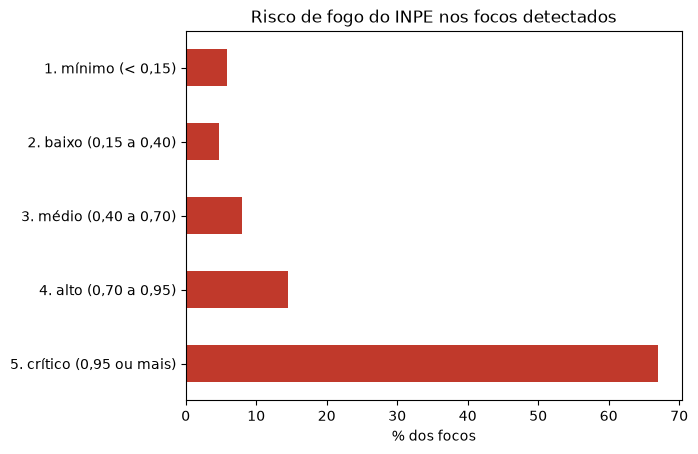

In [8]:
risco = q('''
    SELECT CASE WHEN risco_fogo < 0.15 THEN '1. mínimo (< 0,15)'
                WHEN risco_fogo < 0.40 THEN '2. baixo (0,15 a 0,40)'
                WHEN risco_fogo < 0.70 THEN '3. médio (0,40 a 0,70)'
                WHEN risco_fogo < 0.95 THEN '4. alto (0,70 a 0,95)'
                ELSE '5. crítico (0,95 ou mais)' END AS faixa_inpe,
           count(*) AS focos
    FROM queimadas WHERE risco_fogo >= 0
    GROUP BY 1 ORDER BY 1
''').set_index('faixa_inpe')
risco['%'] = (risco['focos'] / risco['focos'].sum() * 100).round(2)
print(risco)

risco['%'].plot(kind='barh', color=VERMELHO)
plt.gca().invert_yaxis()
plt.title('Risco de fogo do INPE nos focos detectados')
plt.xlabel('% dos focos')
plt.ylabel('')
plt.show()

**67,01% dos focos estão na faixa crítica.** Não é que o Brasil viva em risco crítico: é que o
satélite só registra o risco onde já está queimando. Um modelo treinado só nessas linhas aprenderia "como
é o risco quando já há fogo", não "qual a chance de pegar fogo". Por isso:

1. **A base do modelo é uma grade com todos os municípios em todos os dias**, e o dia sem foco vale zero.
   Esses zeros são os "aviões que não voltaram".
2. **`risco_fogo`, `dias_sem_chuva` e `precipitacao` não entram como features.** Elas só existem quando
   houve foco; usar essas colunas seria contar ao modelo que houve fogo.
3. **O bioma também fica de fora como feature.** A única fonte de bioma por município é a própria base de
   queimadas: um município sem nenhum foco ficaria com bioma vazio, o que entregaria a resposta. O bioma
   aparece só nos gráficos.

## 4. Construção do alvo

### 4.1. Qual satélite contar

Vários satélites registram o mesmo fogo, e os geoestacionários (GOES-16 e MSG-03) fotografam a mesma
região a cada poucos minutos:

In [9]:
satelites = q('''
    SELECT satelite, count(*) AS focos, count(DISTINCT (id_municipio, CAST(data_hora AS DATE))) AS municipio_dias
    FROM queimadas GROUP BY 1 ORDER BY 2 DESC
''')
satelites['focos por município-dia'] = (satelites['focos'] / satelites['municipio_dias']).round(2)
satelites

,satelite,focos,municipio_dias,focos por município-dia
0,NOAA-20,1983819,191470,10.36
1,NOAA-21,1958410,192473,10.17
2,GOES-16,1542719,50435,30.59
3,NPP-375,1126314,144091,7.82
4,NPP-375D,736834,60858,12.11
5,AQUA_M-T,282164,64777,4.36
6,METOP-B,161081,22789,7.07
7,METOP-C,147944,20733,7.14
8,TERRA_M-M,117983,26275,4.49
9,TERRA_M-T,92409,30213,3.06


O GOES-16 registra 30,59 focos por município-dia com fogo, contra 10,36 do NOAA-20: ele conta o
mesmo incêndio várias vezes ao longo do dia. **A contagem usa só os satélites de órbita polar**, que
passam poucas vezes por dia. O INPE faz algo parecido nas séries históricas, que usam um único satélite de
referência (o AQUA, à tarde). Aqui ele sozinho seria pouco: vê fogo em 64 777 município-dias, um terço do
que o NOAA-20 vê (191 470).

### 4.2. A grade, passo a passo

A consolidação tem 11 passos, todos em SQL, no arquivo `src/consolidar_base.py`. Para cada passo, abaixo
aparecem: o que ele faz e por quê, a consulta SQL comentada linha por linha e o resultado num município de
exemplo, **Altamira (PA), de 13 a 22 de abril de 2024**. Nesses 10 dias aparecem os três níveis de risco.

**SQL em um minuto**, para ler as consultas:

| Comando | O que faz |
|---|---|
| `SELECT` | escolhe as colunas do resultado |
| `FROM` | diz de qual tabela os dados vêm |
| `WHERE` | filtra: só as linhas que passam na condição |
| `GROUP BY` | junta as linhas iguais numa só, para contar ou somar |
| `JOIN` | junta duas tabelas por uma coluna em comum (aqui, o município e o dia) |
| `CASE WHEN … THEN … ELSE … END` | um "se… então… senão" dentro da consulta |
| `CREATE TABLE … AS` | guarda o resultado como uma tabela nova, para o próximo passo usar |
| `WITH` | dá um nome a um resultado intermediário, para a consulta ficar mais fácil de ler |
| `OVER (…)` | função de janela: para cada linha, olha outras linhas do mesmo grupo (por exemplo, o dia anterior do mesmo município) |

Tudo o que vem depois de `--` numa linha é comentário: explica a consulta e não é executado.

In [10]:
EXEMPLO = '''WHERE id_municipio = 1500602 AND dia BETWEEN DATE '2024-04-13' AND DATE '2024-04-22' ORDER BY dia'''

**Passo 1: contar os focos de cada município em cada dia.** Cada linha da base de queimadas é um foco, num
ponto e num horário. Aqui eles viram uma contagem por município e dia. Os satélites geoestacionários ficam
de fora (seção 4.1), e um foco repetido conta uma vez só.

In [11]:
print(cb.contar_focos(con))
q(f'SELECT * FROM focos_dia {EXEMPLO}')

-- Cria a tabela focos_dia: uma linha por município e dia que teve fogo.
CREATE OR REPLACE TABLE focos_dia AS
SELECT
    id_municipio,
    CAST(data_hora AS DATE) AS dia,           -- tira a hora e fica só a data
    COUNT(DISTINCT (data_hora, latitude, longitude, satelite)) AS focos
                                              -- conta focos diferentes (repetidos contam uma vez)
FROM queimadas
WHERE satelite NOT IN ('GOES-16', 'MSG-03')      -- deixa de fora os satélites que repetem o mesmo fogo
GROUP BY id_municipio, dia                    -- junta tudo do mesmo município no mesmo dia


,id_municipio,dia,focos
0,1500602,2024-04-15,1
1,1500602,2024-04-16,1
2,1500602,2024-04-19,5


Repare que Altamira só aparece nos **dias em que houve fogo**. Os outros dias simplesmente não existem
nesta tabela. É o viés de sobrevivência da seção 3: o passo seguinte resolve isso.

**Passo 2: montar a grade com todos os municípios em todos os dias.** A consulta faz duas listas, a dos
municípios (do MapBiomas) e a dos dias (do primeiro ao último dia da base de queimadas), e combina cada
município com cada dia (`CROSS JOIN`). Depois traz a contagem do passo 1 (`LEFT JOIN`). Onde não há
contagem, o dia não teve foco, e `COALESCE` põe 0.

In [12]:
print(cb.montar_grade(con))
q(f'SELECT * FROM grade {EXEMPLO}')

-- Cria a tabela grade: uma linha para cada município em cada dia do período.
CREATE OR REPLACE TABLE grade AS
WITH
    -- a lista de municípios, tirada do MapBiomas
    municipios AS (SELECT DISTINCT id_municipio, sigla_uf FROM mapbiomas),
    -- a lista de todos os dias, do primeiro ao último dia com foco na base
    dias AS (
        SELECT CAST(dia AS DATE) AS dia
        FROM generate_series(
            (SELECT MIN(CAST(data_hora AS DATE)) FROM queimadas),
            (SELECT MAX(CAST(data_hora AS DATE)) FROM queimadas),
            INTERVAL 1 DAY) AS t(dia)
    )
SELECT
    m.id_municipio,
    m.sigla_uf,
    d.dia,
    COALESCE(f.focos, 0) AS focos             -- se o dia não teve foco, vale 0
FROM municipios m
CROSS JOIN dias d                             -- combina cada município com cada dia
LEFT JOIN focos_dia f                         -- traz os focos do passo 1, quando existem
    ON f.id_municipio = m.id_municipio AND f.dia = d.dia


,id_municipio,sigla_uf,dia,focos
0,1500602,PA,2024-04-13,0
1,1500602,PA,2024-04-14,0
2,1500602,PA,2024-04-15,1
3,1500602,PA,2024-04-16,1
4,1500602,PA,2024-04-17,0
5,1500602,PA,2024-04-18,0
6,1500602,PA,2024-04-19,5
7,1500602,PA,2024-04-20,0
8,1500602,PA,2024-04-21,0
9,1500602,PA,2024-04-22,0


Agora os 10 dias aparecem, e os dias sem fogo valem 0.

**Passo 3: o histórico de focos.** Para cada dia, a consulta olha para trás, sempre no mesmo município: os
focos de ontem, a soma dos últimos 7 e dos últimos 30 dias e quantos desses 30 dias tiveram fogo. A janela
termina **na véspera** (`1 PRECEDING`), nunca no próprio dia: o modelo não pode ver o fogo que vai prever.

In [13]:
print(cb.criar_historico(con))
q(f'SELECT dia, focos, focos_ontem, focos_7d, focos_30d, dias_com_foco_30d FROM grade {EXEMPLO}')

-- Acrescenta à grade o histórico de focos de cada município.
-- "OVER (PARTITION BY ... ORDER BY ...)" é uma função de janela: para cada linha,
-- olha as outras linhas do MESMO município, em ordem de data.
CREATE OR REPLACE TABLE grade AS
SELECT
    *,
    LAG(focos, 1) OVER janela AS focos_ontem, -- o valor de focos na linha anterior (ontem)
    SUM(focos) OVER (janela ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING) AS focos_7d,
                                              -- soma dos 7 dias anteriores (sem hoje)
    SUM(focos) OVER (janela ROWS BETWEEN 30 PRECEDING AND 1 PRECEDING) AS focos_30d,
                                              -- soma dos 30 dias anteriores (sem hoje)
    SUM(CASE WHEN focos > 0 THEN 1 ELSE 0 END)
        OVER (janela ROWS BETWEEN 30 PRECEDING AND 1 PRECEDING) AS dias_com_foco_30d,
                                              -- quantos dos 30 dias anteriores tiveram fogo
    ROW_NUMBER() OVER janela AS dia_da_serie  -- 1 no primeiro dia, 2 no segundo... 

,dia,focos,focos_ontem,focos_7d,focos_30d,dias_com_foco_30d
0,2024-04-13,0,0,3.0,25.0,11.0
1,2024-04-14,0,0,3.0,21.0,10.0
2,2024-04-15,1,0,1.0,16.0,9.0
3,2024-04-16,1,1,2.0,17.0,10.0
4,2024-04-17,0,1,3.0,18.0,11.0
5,2024-04-18,0,0,3.0,18.0,11.0
6,2024-04-19,5,0,2.0,16.0,10.0
7,2024-04-20,0,5,7.0,21.0,11.0
8,2024-04-21,0,0,7.0,21.0,11.0
9,2024-04-22,0,0,7.0,21.0,11.0


Para conferir: em 19 de abril Altamira teve 5 focos; no dia seguinte, `focos_ontem` vale 5. O fogo de hoje
só entra no histórico a partir de amanhã.

**Passo 4: juntar o clima de hora em hora.** As medições do INMET 2024 (um arquivo por estação) e do BDMEP
2025 vão para uma tabela só, empilhadas (`UNION ALL`). O código `-9999`, que o INMET usa para "sem medição",
vira vazio (`NULLIF`), e as linhas em dobro do BDMEP viram uma só (`SELECT DISTINCT`).

In [14]:
print(cb.ler_clima_horario(con))
q('SELECT count(*) AS medicoes, count(DISTINCT id_estacao) AS estacoes, min(dia) AS primeiro_dia, max(dia) AS ultimo_dia FROM clima_horario')

-- Cria a tabela clima_horario: uma linha por estação e hora, de 2024 até o último dia da grade.
CREATE OR REPLACE TABLE clima_horario AS
SELECT
    split_part(parse_filename(filename), '_', 4) AS id_estacao,
                                              -- o código da estação está no nome do arquivo
    CAST(data AS DATE) AS dia,
    NULLIF(chuva, -9999) AS chuva,            -- o INMET usa -9999 para "sem medição"
    NULLIF(temp_max, -9999) AS temp_max,
    NULLIF(umidade_min, -9999) AS umidade_min,
    NULLIF(vento, -9999) AS vento
FROM inmet_2024
UNION ALL                                     -- empilha embaixo as linhas de 2025
SELECT id_estacao, CAST(data AS DATE), precipitacao_total, temperatura_max, umidade_rel_min, vento_velocidade
FROM (SELECT DISTINCT * FROM bdmep)           -- o BDMEP vem com as linhas em dobro: fica uma de cada
WHERE data <= (SELECT MAX(dia) FROM grade)


,medicoes,estacoes,primeiro_dia,ultimo_dia
0,5546050,565,2024-01-01,2025-02-12


**Passo 5: um valor por estação e dia.** Para cada estação e dia: a umidade mais baixa, a temperatura mais
alta, a chuva somada e o vento médio. Se a estação mediu menos de 18 das 24 horas, o valor daquele dia
fica vazio: um dia com metade das horas medidas não representa o dia.

In [15]:
print(cb.agregar_clima_diario(con))
q('''SELECT count(*) AS estacao_dias,
         round(100 * avg((umidade_min IS NOT NULL)::INT), 1) AS pct_com_umidade,
         round(100 * avg((temp_max IS NOT NULL)::INT), 1) AS pct_com_temperatura,
         round(100 * avg((chuva IS NOT NULL)::INT), 1) AS pct_com_chuva
     FROM clima_diario''')

-- Um valor diário só vale se a estação mediu pelo menos 18 das 24 horas.
CREATE OR REPLACE TABLE clima_diario AS
SELECT
    id_estacao,
    dia,
    CASE WHEN COUNT(umidade_min) >= 18 THEN MIN(umidade_min) END AS umidade_min,
                                              -- a umidade mais baixa do dia (%)
    CASE WHEN COUNT(temp_max) >= 18 THEN MAX(temp_max) END AS temp_max,
                                              -- a temperatura mais alta do dia (°C)
    CASE WHEN COUNT(chuva) >= 18 THEN CAST(SUM(CAST(chuva AS DECIMAL(9, 2))) AS DOUBLE) END AS chuva,
                                              -- a chuva somada do dia (mm); somar em DECIMAL é exato
                                              -- e dá sempre o mesmo resultado, em qualquer ordem
    CASE WHEN COUNT(vento) >= 18 THEN CAST(ROUND(AVG(CAST(vento AS DECIMAL(9, 2))), 2) AS DOUBLE) END AS vento
                                              -- a velocidade média do vento no dia (m/s)
FROM clima_horario
GROUP BY id_e

,estacao_dias,pct_com_umidade,pct_com_temperatura,pct_com_chuva
0,230956,72.8,79.4,71.9


**Passo 6: a estação mais próxima de cada município.** Só entram as estações "boas", que mediram a umidade
em pelo menos 80% dos dias. Para cada município, a consulta calcula a distância da sede até cada estação boa
(fórmula de Haversine, que mede a distância sobre a superfície da Terra) e fica com a mais próxima.

In [16]:
print(cb.ligar_estacao_proxima(con))
print('Estações boas:', q('SELECT count(*) AS n FROM estacoes_boas')['n'].iloc[0])
distancias = q('SELECT distancia_estacao_km FROM estacao_proxima')['distancia_estacao_km']
for limite in [50, 100, 150]:
    print(f'Municípios com estação boa a até {limite} km: {(distancias <= limite).mean():.1%}')
print(f'Distância mediana: {distancias.median():.1f} km')
q('SELECT * FROM estacao_proxima WHERE id_municipio = 1500602').round(1)

-- Coordenadas das estações: do cabeçalho dos arquivos de 2024 e, para as que faltarem, do cadastro do BDMEP.
CREATE OR REPLACE TABLE coordenadas AS
SELECT id_estacao, latitude, longitude FROM coordenadas_2024
UNION
SELECT id_estacao, latitude, longitude FROM estacoes
WHERE id_estacao NOT IN (SELECT id_estacao FROM coordenadas_2024);

-- Estação "boa": mediu a umidade em pelo menos 80% dos dias.
CREATE OR REPLACE TABLE estacoes_boas AS
SELECT id_estacao
FROM clima_diario
GROUP BY id_estacao
HAVING AVG(CASE WHEN umidade_min IS NOT NULL THEN 1 ELSE 0 END) >= 0.8;

-- Distância em km entre a sede de cada município e cada estação boa (fórmula de Haversine,
-- que mede a distância sobre a superfície da Terra) e, para cada município, a mais próxima.
CREATE OR REPLACE TABLE estacao_proxima AS
WITH distancias AS (
    SELECT
        m.codigo_ibge AS id_municipio,
        c.id_estacao,
        2 * 6371 * ASIN(SQRT(
            POWER(SIN(RADIANS(c.latitude - m.latitude) / 2), 2)
            + CO

,id_municipio,id_estacao,distancia_estacao_km
0,1500602,A253,21.8


Metade dos municípios tem uma estação boa a até 48,6 km da sede. O limite adotado é de **150 km**: até
essa distância, o clima da estação ainda descreve o município, e 95,7% dos municípios ficam cobertos. Acima
dele, o clima fica vazio. Os municípios mais longe de estação estão sobretudo na Amazônia, onde a rede de
estações é rala.

*Transparência:* a escolha das estações boas olha a cobertura de dados do período inteiro, inclusive os meses
que vão servir de teste na Etapa 2 (os dias guardados para dar a nota final do modelo). Isso não entrega a resposta, porque depende só de a estação ter medido, e
não de ter havido fogo; num uso real, a escolha seria feita só com o histórico disponível até a data.

**Passo 7: o clima da véspera.** O clima de cada dia é trazido da estação do município e depois deslocado
um dia para trás (`LAG`), como o histórico de focos: o modelo só vê o clima de **até ontem**. Também entra a
chuva somada nos 7 dias anteriores.

In [17]:
print(cb.criar_clima_vespera(con))
q(f'SELECT dia, focos, umidade_min_ontem, temp_max_ontem, chuva_ontem, chuva_7d FROM grade {EXEMPLO}')

-- Primeiro, traz para cada município e dia o clima medido naquele dia na sua estação.
-- Município a mais de 150 km da estação fica sem clima (vazio).
CREATE OR REPLACE TABLE grade AS
SELECT g.*, p.distancia_estacao_km, c.umidade_min, c.temp_max, c.chuva, c.vento
FROM grade g
LEFT JOIN estacao_proxima p
    ON p.id_municipio = g.id_municipio AND p.distancia_estacao_km <= 150
LEFT JOIN clima_diario c
    ON c.id_estacao = p.id_estacao AND c.dia = g.dia;

-- Depois, desloca tudo um dia para trás: o modelo só pode ver o clima de ATÉ ONTEM.
-- O clima do próprio dia sai da tabela no fim.
CREATE OR REPLACE TABLE grade AS
SELECT
    * EXCLUDE (umidade_min, temp_max, chuva, vento),
    LAG(umidade_min, 1) OVER janela AS umidade_min_ontem,
    LAG(temp_max, 1) OVER janela AS temp_max_ontem,
    LAG(chuva, 1) OVER janela AS chuva_ontem,
    LAG(vento, 1) OVER janela AS vento_ontem,
    CAST(SUM(CAST(chuva AS DECIMAL(9, 2))) OVER (janela ROWS BETWEEN 7 PRECEDING AND 1 PRECEDING) AS DOUBLE) AS c

,dia,focos,umidade_min_ontem,temp_max_ontem,chuva_ontem,chuva_7d
0,2024-04-13,0,73.0,31.5,1.2,144.0
1,2024-04-14,0,86.0,28.3,37.0,150.0
2,2024-04-15,1,79.0,30.0,1.2,151.0
3,2024-04-16,1,61.0,32.2,1.0,144.4
4,2024-04-17,0,70.0,32.0,43.6,96.2
5,2024-04-18,0,64.0,33.5,8.2,104.2
6,2024-04-19,5,66.0,31.8,1.2,93.4
7,2024-04-20,0,65.0,32.0,7.2,99.4
8,2024-04-21,0,61.0,32.4,39.8,102.2
9,2024-04-22,0,73.0,30.2,23.2,124.2


**Passo 8: o calendário.** O mês e o dia do ano, porque o fogo tem estação (seção 5.1).

In [18]:
print(cb.criar_calendario(con))
q(f'SELECT dia, mes, dia_do_ano FROM grade {EXEMPLO} LIMIT 3')

CREATE OR REPLACE TABLE grade AS
SELECT
    *,
    MONTH(dia) AS mes,                        -- 1 a 12
    DAYOFYEAR(dia) AS dia_do_ano              -- 1 a 366
FROM grade

,dia,mes,dia_do_ano
0,2024-04-13,4,104
1,2024-04-14,4,105
2,2024-04-15,4,106


**Passo 9: o uso do solo.** Primeiro, uma tabela com uma linha por município: a área total em 2021, a
proporção de cada grupo de uso do solo (floresta, pastagem, agricultura…) e quanto de vegetação nativa foi
perdido entre 2016 e 2021. Depois, esses valores são colados em todos os dias do município: eles não mudam
de um dia para o outro.

In [19]:
print(cb.criar_uso_do_solo(con))
q('SELECT * EXCLUDE (id_municipio) FROM uso_solo WHERE id_municipio = 1500602').round(3).T.rename(columns={0: 'Altamira'})

-- Primeiro, uma tabela com uma linha por município.
CREATE OR REPLACE TABLE uso_solo AS
SELECT
    id_municipio,
    SUM(CASE WHEN ano = 2021 THEN area ELSE 0 END) AS area_km2,
                                              -- área total do município em 2021
    -- para cada grupo: área do grupo em 2021 ÷ área total = proporção de 0 a 1
    SUM(CASE WHEN ano = 2021 AND id_classe IN (3, 4, 5, 49) THEN area ELSE 0 END)
        / SUM(CASE WHEN ano = 2021 THEN area ELSE 0 END) AS pct_floresta,
    SUM(CASE WHEN ano = 2021 AND id_classe IN (11, 12, 13, 29, 32, 50) THEN area ELSE 0 END)
        / SUM(CASE WHEN ano = 2021 THEN area ELSE 0 END) AS pct_natural_nao_florestal,
    SUM(CASE WHEN ano = 2021 AND id_classe IN (15) THEN area ELSE 0 END)
        / SUM(CASE WHEN ano = 2021 THEN area ELSE 0 END) AS pct_pastagem,
    SUM(CASE WHEN ano = 2021 AND id_classe IN (9, 20, 39, 40, 41, 46, 47, 48, 62) THEN area ELSE 0 END)
        / SUM(CASE WHEN ano = 2021 THEN area ELSE 0 END) AS pct_agricultur

,Altamira
area_km2,159533.217
pct_floresta,0.913
pct_natural_nao_florestal,0.005
pct_pastagem,0.071
pct_agricultura,0.001
pct_mosaico,0.000
pct_nao_vegetada,0.000
pct_agua,0.010
perda_nativa_5a,0.029


Altamira é quase toda floresta, e é um dos maiores municípios do país.

**Passo 10: o alvo.** O nível de risco do dia, com um "se… então… senão": 4 ou mais focos é Alto, de 1 a 3 é
Médio, nenhum é Baixo.

In [20]:
print(cb.criar_alvo(con))
q(f'SELECT dia, focos, nivel_risco FROM grade {EXEMPLO}')

CREATE OR REPLACE TABLE grade AS
SELECT
    *,
    CASE
        WHEN focos >= 4 THEN 'Alto'      -- 4 ou mais focos
        WHEN focos >= 1 THEN 'Médio'    -- 1 a 3 focos
        ELSE 'Baixo'                         -- nenhum foco
    END AS nivel_risco
FROM grade


,dia,focos,nivel_risco
0,2024-04-13,0,Baixo
1,2024-04-14,0,Baixo
2,2024-04-15,1,Médio
3,2024-04-16,1,Médio
4,2024-04-17,0,Baixo
5,2024-04-18,0,Baixo
6,2024-04-19,5,Alto
7,2024-04-20,0,Baixo
8,2024-04-21,0,Baixo
9,2024-04-22,0,Baixo


**Passo 11: tirar os primeiros 30 dias.** De 1º a 30 de janeiro de 2024 não há 30 dias de passado para
calcular o histórico. Preencher com zero seria inventar que não houve fogo antes; por isso esses dias saem.

In [21]:
print(cb.remover_sem_historico(con))
q('SELECT min(dia) AS primeiro_dia, max(dia) AS ultimo_dia, count(DISTINCT id_municipio) AS municipios, count(*) AS linhas FROM grade')

CREATE OR REPLACE TABLE grade AS
SELECT * EXCLUDE (dia_da_serie)               -- todas as colunas, menos a auxiliar do passo 3
FROM grade
WHERE dia_da_serie > 30                 -- só a partir do 31º dia da série
ORDER BY id_municipio, dia


,primeiro_dia,ultimo_dia,municipios,linhas
0,2024-01-31,2025-02-12,5566,2109514


A grade final tem **2 109 514 linhas**: 5 566 municípios em 379 dias, de 31 de janeiro de 2024 a 12 de
fevereiro de 2025.

### 4.3. Os cortes de Baixo, Médio e Alto

                dias      %
nivel_risco                
Baixo        1810181  85.81
Médio         166502   7.89
Alto          132831   6.30

   municipios  dias   linhas
0        5566   379  2109514


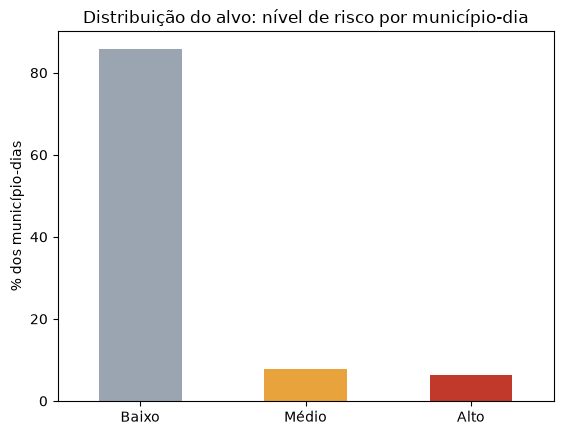

In [22]:
alvo = q("SELECT nivel_risco, count(*) AS dias FROM grade GROUP BY 1").set_index('nivel_risco').loc[['Baixo', 'Médio', 'Alto']]
alvo['%'] = (alvo['dias'] / alvo['dias'].sum() * 100).round(2)
print(alvo)
print()
print(q('SELECT count(DISTINCT id_municipio) AS municipios, count(DISTINCT dia) AS dias, count(*) AS linhas FROM grade'))

alvo['%'].plot(kind='bar', rot=0, color=[CORES_RISCO[n] for n in alvo.index])
plt.title('Distribuição do alvo: nível de risco por município-dia')
plt.ylabel('% dos município-dias')
plt.xlabel('')
plt.show()

**Baixo é o dia sem nenhum foco (85,81%).** Entre os dias com foco, o corte de 4 focos fica logo acima da
mediana (o valor do meio: metade dos dias com fogo tem até 3 focos, seção 5.7) e separa o fogo isolado (Médio, 7,89%) do dia com vários pontos queimando ao mesmo tempo
(Alto, 6,30%), que é o que pede brigada de prontidão. As duas classes menores ficam acima de 5%.

**Limitação:** "nenhum foco detectado" não é exatamente "nenhum fogo". Nuvens e fogos pequenos escapam
do satélite. O alvo mede o fogo **visível por satélite**.

## 5. Exploração

### 5.1. Sazonalidade

     medio   alto
mes              
1     6.65   2.17
2     5.28   1.60
3     5.21   1.60
4     4.19   1.21
5     6.07   3.41
6     7.66   5.33
7     8.56   6.38
8    10.85  12.48
9    11.16  15.42
10   10.70  12.46
11    9.97   8.87
12    9.33   6.47


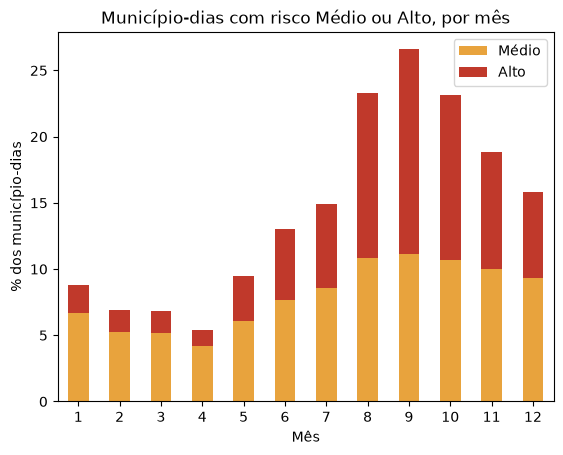

In [23]:
por_mes = q('''
    SELECT mes, avg((nivel_risco = 'Médio')::INT) * 100 AS medio, avg((nivel_risco = 'Alto')::INT) * 100 AS alto
    FROM grade GROUP BY 1 ORDER BY 1
''').set_index('mes').round(2)
print(por_mes)

por_mes.plot(kind='bar', stacked=True, rot=0, color=[LARANJA, VERMELHO])
plt.title('Município-dias com risco Médio ou Alto, por mês')
plt.ylabel('% dos município-dias')
plt.xlabel('Mês')
plt.legend(['Médio', 'Alto'])
plt.show()

**O fogo tem estação.** Em setembro, 15,42% dos município-dias são Alto; em abril, 1,21%. O mês entra como
feature. Na Etapa 2, os dados serão divididos em **treino** (os dias com que o modelo aprende) e **teste**
(os dias guardados para dar a nota final), e essa divisão vai precisar respeitar o calendário.

### 5.2. Persistência: o fogo de ontem

             pct_fogo_hoje  pct_alto_hoje     dias
focos_ontem                                       
0                     7.74           1.91  1810040
1 a 3                36.70          14.53   166579
4 a 10               60.56          35.77    67735
mais de 10           87.61          76.33    65160


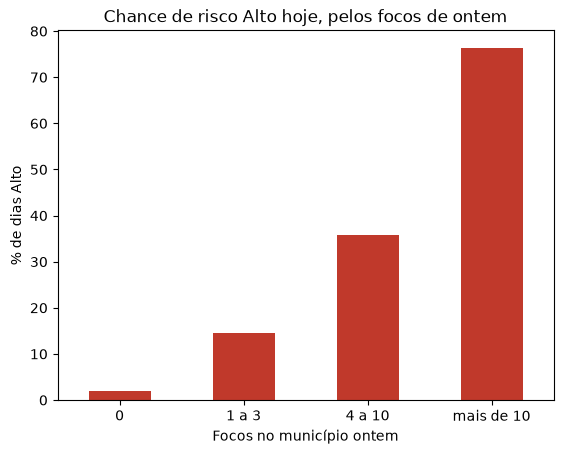

In [24]:
persistencia = q('''
    SELECT CASE WHEN focos_ontem = 0 THEN '0' WHEN focos_ontem <= 3 THEN '1 a 3'
                WHEN focos_ontem <= 10 THEN '4 a 10' ELSE 'mais de 10' END AS focos_ontem,
           avg((focos > 0)::INT) * 100 AS pct_fogo_hoje, avg((nivel_risco = 'Alto')::INT) * 100 AS pct_alto_hoje,
           count(*) AS dias
    FROM grade GROUP BY 1 ORDER BY min(focos_ontem)
''').set_index('focos_ontem').round(2)
print(persistencia)

persistencia['pct_alto_hoje'].plot(kind='bar', rot=0, color=VERMELHO)
plt.title('Chance de risco Alto hoje, pelos focos de ontem')
plt.ylabel('% de dias Alto')
plt.xlabel('Focos no município ontem')
plt.show()

**O fogo de ontem é o melhor aviso para hoje.** Sem foco ontem, só 1,91% dos dias são Alto; com mais
de 10 focos ontem, 76,33%. Isso vira o teste de hipótese 1 (seção 7) e o **modelo de referência**
da seção 8.

### 5.3. Estados e biomas

          pct_alto  municipios
sigla_uf                      
DF           44.33           1
RR           38.77          15
PA           26.05         143
AC           24.71          22
MT           22.41         141
AM           21.73          62
MA           20.03         217
TO           17.00         139


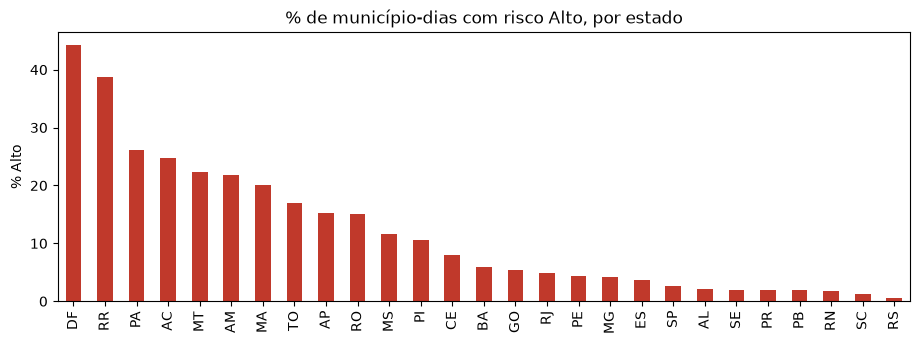

In [25]:
por_uf = q('''
    SELECT sigla_uf, avg((nivel_risco = 'Alto')::INT) * 100 AS pct_alto, count(DISTINCT id_municipio) AS municipios
    FROM grade GROUP BY 1 ORDER BY 2 DESC
''').set_index('sigla_uf').round(2)
print(por_uf.head(8))

por_uf['pct_alto'].plot(kind='bar', color=VERMELHO, figsize=(11, 3.5))
plt.title('% de município-dias com risco Alto, por estado')
plt.ylabel('% Alto')
plt.xlabel('')
plt.show()

In [26]:
por_bioma = q('''
    SELECT bioma, count(*) AS focos, round(100 * count(*) / sum(count(*)) OVER (), 2) AS pct_focos
    FROM queimadas WHERE satelite NOT IN ('GOES-16', 'MSG-03') GROUP BY 1 ORDER BY 2 DESC
''')
por_bioma

,bioma,focos,pct_focos
0,Amazônia,3555180,53.44
1,Cerrado,1892561,28.45
2,Pantanal,441487,6.64
3,Mata Atlântica,410817,6.18
4,Caatinga,343606,5.17
5,Pampa,8874,0.13
6,NaN,1,0.00


- **Estados:** Roraima (38,77%), Pará (26,05%) e Acre (24,71%) lideram em dias de risco Alto. O DF aparece
  no topo (44,33%), mas é um caso à parte: é um único município, e grande. O estado entra como feature.
- **Biomas:** Amazônia (53,44%) e Cerrado (28,45%) concentram a maior parte dos focos. O bioma fica só na análise, pelo motivo
  da seção 3.

### 5.4. Uso do solo

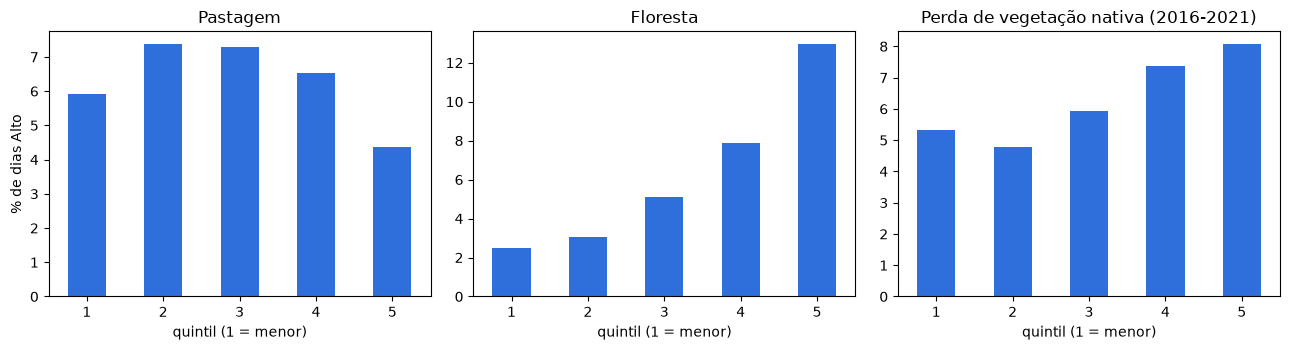

pct_pastagem     quintil menor: 5.91% Alto | quintil maior: 4.36% Alto
pct_floresta     quintil menor: 2.47% Alto | quintil maior: 12.96% Alto
perda_nativa_5a  quintil menor: 5.34% Alto | quintil maior: 8.08% Alto


In [27]:
municipios = q('''
    SELECT id_municipio, avg((nivel_risco = 'Alto')::INT) * 100 AS pct_alto,
           any_value(pct_pastagem) AS pct_pastagem, any_value(pct_floresta) AS pct_floresta,
           any_value(perda_nativa_5a) AS perda_nativa_5a
    FROM grade GROUP BY 1
''')
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
for eixo, coluna, titulo in zip(eixos, ['pct_pastagem', 'pct_floresta', 'perda_nativa_5a'],
                                ['Pastagem', 'Floresta', 'Perda de vegetação nativa (2016-2021)']):
    faixa = pd.qcut(municipios[coluna], 5, duplicates='drop')
    municipios.groupby(faixa, observed=True)['pct_alto'].mean().plot(kind='bar', ax=eixo, color=AZUL, rot=0)
    eixo.set_title(titulo)
    eixo.set_xlabel('quintil (1 = menor)')
    eixo.set_xticklabels(range(1, len(eixo.get_xticks()) + 1))
eixos[0].set_ylabel('% de dias Alto')
plt.tight_layout()
plt.show()

for coluna in ['pct_pastagem', 'pct_floresta', 'perda_nativa_5a']:
    faixa = pd.qcut(municipios[coluna], 5, labels=False, duplicates='drop')
    taxa = municipios.groupby(faixa)['pct_alto'].mean()
    print(f'{coluna:<16} quintil menor: {taxa.iloc[0]:.2f}% Alto | quintil maior: {taxa.iloc[-1]:.2f}% Alto')

Nos gráficos abaixo, os municípios são divididos em **quintis**: 5 grupos do mesmo tamanho, do que tem menos
(quintil 1) ao que tem mais (quintil 5) de cada característica. A barra mostra a fração de dias Alto em cada
grupo.

- **Floresta é o que mais separa:** no quintil de municípios mais florestados, 12,96% dos dias são Alto, contra
  2,47% no menos florestado. São, em boa parte, os municípios da Amazônia, que também são os maiores
  (a área do município aparece na seção 6).
- **Perda de vegetação nativa:** quem mais perdeu vegetação nativa entre 2016 e 2021 tem 8,08% de dias Alto,
  contra 5,34% de quem menos perdeu. Faz sentido: queimada é uma das formas de abrir área.
- **Pastagem não tem relação clara com o risco:** a taxa sobe e desce entre os quintis (5,91% no menor,
  4,36% no maior).

O uso do solo carrega informação mesmo sendo de 2021.

### 5.5. O clima da véspera

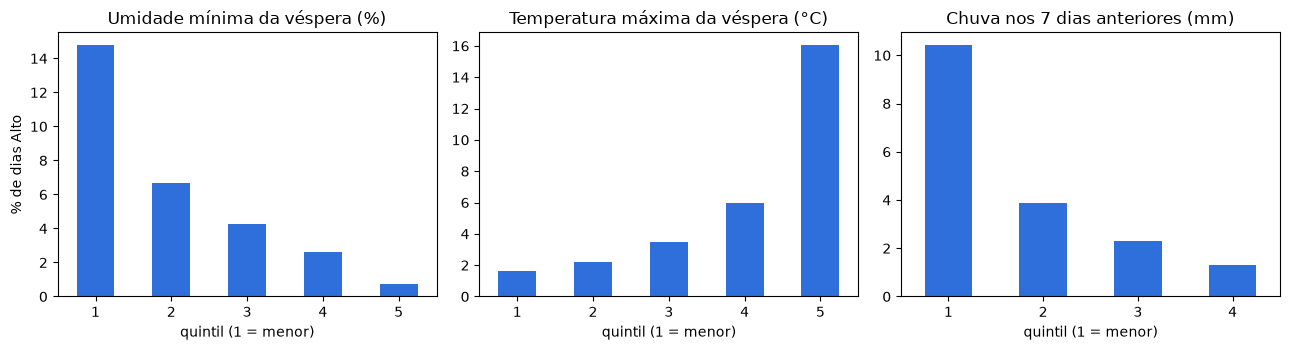

             umidade_min_ontem  temp_max_ontem  chuva_7d
nivel_risco                                             
Baixo                    47.74           29.83     29.51
Médio                    38.40           31.93     13.98
Alto                     32.36           33.86      7.62


In [28]:
clima = q('''
    SELECT nivel_risco, umidade_min_ontem, temp_max_ontem, chuva_7d
    FROM grade USING SAMPLE 300000 ROWS (reservoir, 12345)
''')
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.6))
for eixo, coluna, titulo in zip(eixos, ['umidade_min_ontem', 'temp_max_ontem', 'chuva_7d'],
                                ['Umidade mínima da véspera (%)', 'Temperatura máxima da véspera (°C)',
                                 'Chuva nos 7 dias anteriores (mm)']):
    faixa = pd.qcut(clima[coluna], 5, duplicates='drop')
    (clima.assign(alto=clima['nivel_risco'] == 'Alto').groupby(faixa, observed=True)['alto'].mean() * 100).plot(
        kind='bar', ax=eixo, color=AZUL, rot=0)
    eixo.set_title(titulo)
    eixo.set_xlabel('quintil (1 = menor)')
    eixo.set_xticklabels(range(1, len(eixo.get_xticks()) + 1))
eixos[0].set_ylabel('% de dias Alto')
plt.tight_layout()
plt.show()

print(q('''SELECT nivel_risco, round(avg(umidade_min_ontem), 2) AS umidade_min_ontem,
                  round(avg(temp_max_ontem), 2) AS temp_max_ontem, round(avg(chuva_7d), 2) AS chuva_7d
           FROM grade GROUP BY 1 ORDER BY CASE nivel_risco WHEN 'Baixo' THEN 0 WHEN 'Médio' THEN 1 ELSE 2 END''').set_index('nivel_risco'))

**O clima da véspera separa bem os níveis de risco.** Na média, os dias Alto vêm depois de uma véspera com
umidade mínima de **32,36%**, contra **47,74%** antes dos dias Baixo; temperatura máxima de 33,86 °C,
contra 29,83 °C; e 7,62 mm de chuva na semana anterior, contra 29,51 mm. Os três gráficos mostram a mesma escada:
quanto mais seco e quente, maior a fração de dias Alto. (No gráfico da chuva aparecem só 4 faixas: muitos dias
têm zero de chuva na semana, e as duas primeiras faixas se juntam.)

### 5.6. A distribuição das variáveis

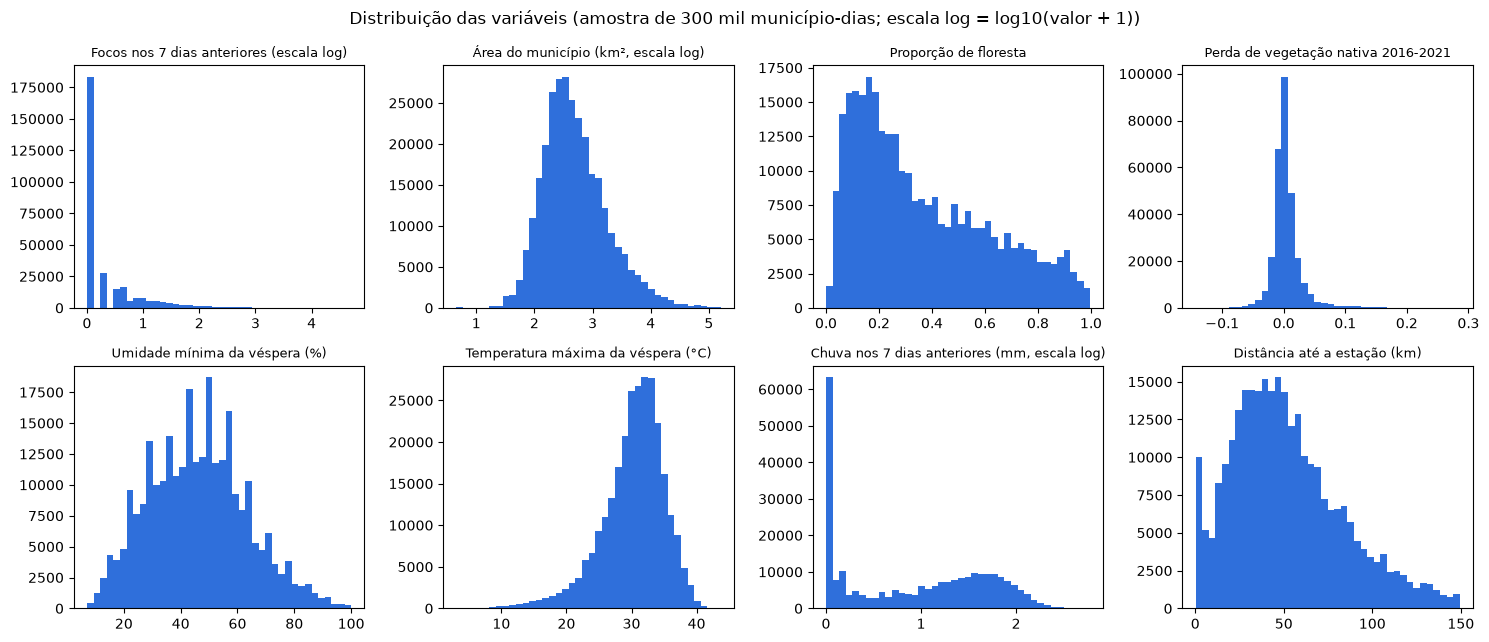

In [29]:
amostra_var = q('''
    SELECT focos_7d, area_km2, pct_floresta, perda_nativa_5a, umidade_min_ontem, temp_max_ontem, chuva_7d,
           distancia_estacao_km
    FROM grade USING SAMPLE 300000 ROWS (reservoir, 12345)
''')
titulos = {'focos_7d': 'Focos nos 7 dias anteriores (escala log)', 'area_km2': 'Área do município (km², escala log)',
           'pct_floresta': 'Proporção de floresta', 'perda_nativa_5a': 'Perda de vegetação nativa 2016-2021',
           'umidade_min_ontem': 'Umidade mínima da véspera (%)', 'temp_max_ontem': 'Temperatura máxima da véspera (°C)',
           'chuva_7d': 'Chuva nos 7 dias anteriores (mm, escala log)', 'distancia_estacao_km': 'Distância até a estação (km)'}
fig, eixos = plt.subplots(2, 4, figsize=(15, 6.5))
for eixo, (coluna, titulo) in zip(eixos.flat, titulos.items()):
    valores = amostra_var[coluna].dropna()
    if 'log' in titulo:
        valores = np.log10(valores + 1)
    eixo.hist(valores, bins=40, color=AZUL)
    eixo.set_title(titulo, fontsize=9)
plt.suptitle('Distribuição das variáveis (amostra de 300 mil município-dias; escala log = log10(valor + 1))')
plt.tight_layout()
plt.show()

- **Focos e chuva** têm cauda longa: quase todos os dias têm zero ou pouco, e poucos dias têm muito. Por isso
  aparecem em **escala log**, em que cada passo do eixo multiplica o valor por 10; assim, dá para ver no mesmo
  gráfico dias com 1 foco e dias com milhares. Isso importa para a Etapa 2: alguns modelos funcionam por
  perguntas do tipo "é maior que X?" (os de **árvore de decisão**) e não se incomodam com valores enormes;
  outros somam pesos de cada coluna (como a **regressão logística**) e precisam dessa transformação.
- **Área do município** também varia muito, de poucos km² a mais de 150 mil (Altamira).
- **Umidade e temperatura** têm distribuições mais comportadas, sem valores impossíveis.
- **Distância até a estação:** a maioria dos municípios fica a menos de 100 km; os vazios do clima vêm
  sobretudo dos poucos acima de 150 km.

### 5.7. Outliers e dados faltantes na base processada

In [30]:
print(q('SELECT quantile_cont(focos, [0.5, 0.9, 0.99, 0.999]) AS quantis, max(focos) AS maximo FROM grade WHERE focos > 0'))
print()
faltantes = q('''SELECT
    round(100 * avg((focos_ontem IS NULL)::INT), 2) AS sem_historico,
    round(100 * avg((pct_floresta IS NULL)::INT), 2) AS sem_uso_do_solo,
    round(100 * avg((distancia_estacao_km IS NULL)::INT), 2) AS sem_estacao_a_150km,
    round(100 * avg((umidade_min_ontem IS NULL)::INT), 2) AS sem_umidade_ontem,
    round(100 * avg((temp_max_ontem IS NULL)::INT), 2) AS sem_temperatura_ontem,
    round(100 * avg((chuva_7d IS NULL)::INT), 2) AS sem_chuva_7d
    FROM grade''')
faltantes.T.rename(columns={0: '% de município-dias vazios'})

                        quantis  maximo
0  [3.0, 29.0, 356.0, 1847.004]   10620



,% de município-dias vazios
sem_historico,0.00
sem_uso_do_solo,0.00
sem_estacao_a_150km,4.33
sem_umidade_ontem,7.64
sem_temperatura_ontem,7.39
sem_chuva_7d,14.85


- **Outliers** (valores muito fora do padrão): há município-dias com até 10 620 focos, muito acima da mediana de
  3 nos dias com fogo. São incêndios grandes reais, não erros. Como o alvo agrupa tudo a partir de 4 focos
  em "Alto", esses extremos não distorcem o alvo; e os modelos de árvore de decisão não se incomodam com
  valores enormes no histórico. **Ficam.**
- **Dados faltantes:** o histórico de focos e o uso do solo estão completos. O clima tem vazios: 4,33% dos
  município-dias não têm estação boa a até 150 km, e 7,64% ficam sem a umidade da véspera (somando os
  municípios sem estação e os dias em que a estação falhou). **Esses vazios ficam vazios**: preencher com
  uma média agora usaria a base inteira, inclusive o futuro, o que é vazamento. Na Etapa 2, o preenchimento
  é feito dentro do treino, e o modelo também recebe a informação de que o valor estava vazio.

## 6. Correlação

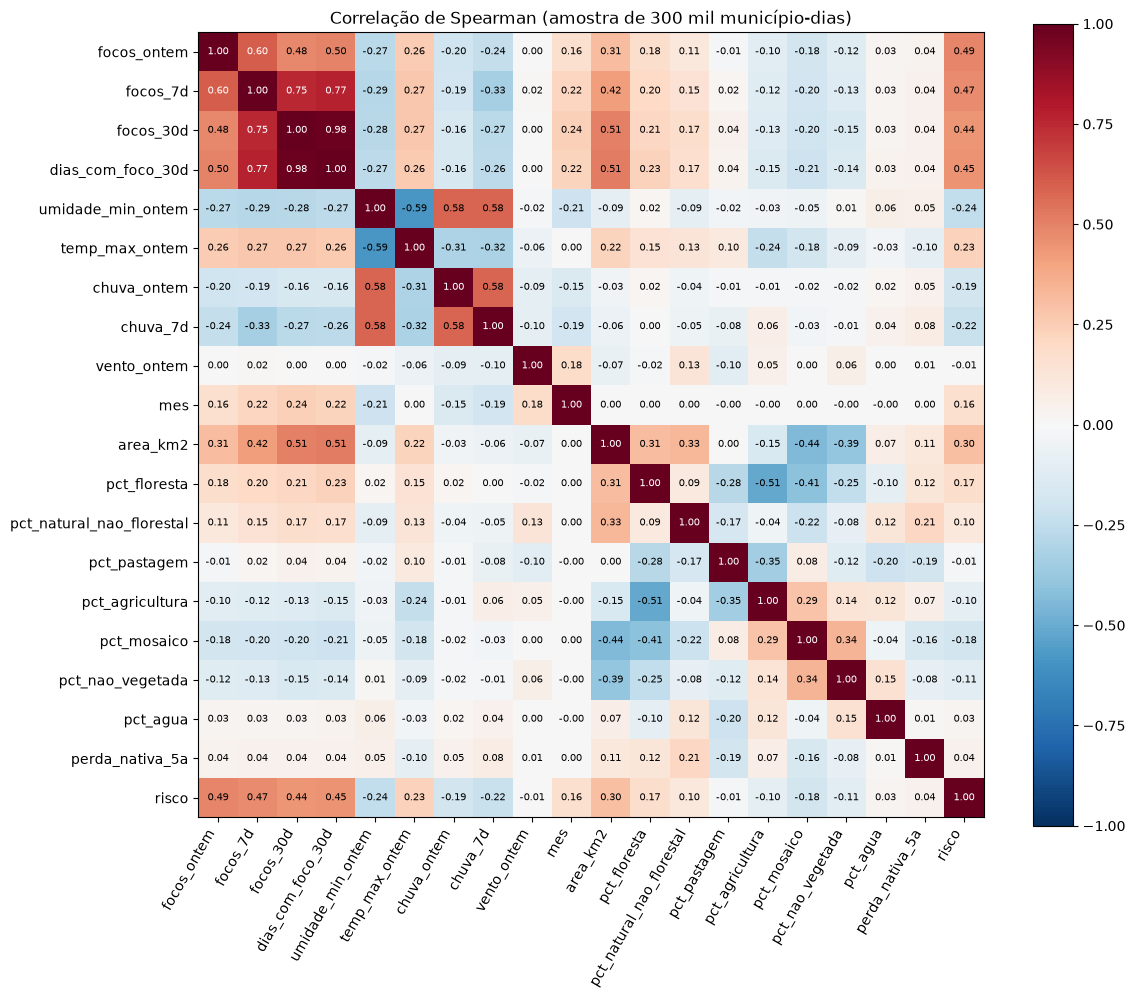

focos_ontem                  0.490
focos_7d                     0.470
dias_com_foco_30d            0.449
focos_30d                    0.442
area_km2                     0.304
temp_max_ontem               0.229
pct_floresta                 0.173
mes                          0.161
pct_natural_nao_florestal    0.104
perda_nativa_5a              0.039
pct_agua                     0.026
vento_ontem                 -0.005
pct_pastagem                -0.014
pct_agricultura             -0.100
pct_nao_vegetada            -0.115
pct_mosaico                 -0.180
chuva_ontem                 -0.187
chuva_7d                    -0.225
umidade_min_ontem           -0.244
Name: risco, dtype: float64

Correlação entre umidade e temperatura da véspera: -0.586


In [31]:
features = ['focos_ontem', 'focos_7d', 'focos_30d', 'dias_com_foco_30d', 'umidade_min_ontem', 'temp_max_ontem',
            'chuva_ontem', 'chuva_7d', 'vento_ontem', 'mes', 'area_km2', 'pct_floresta', 'pct_natural_nao_florestal',
            'pct_pastagem', 'pct_agricultura', 'pct_mosaico', 'pct_nao_vegetada', 'pct_agua', 'perda_nativa_5a']
amostra = q(f'''
    SELECT {', '.join(features)}, CASE nivel_risco WHEN 'Baixo' THEN 0 WHEN 'Médio' THEN 1 ELSE 2 END AS risco
    FROM grade USING SAMPLE 300000 ROWS (reservoir, 12345)
''')
correlacao = amostra.corr(method='spearman')

fig, eixo = plt.subplots(figsize=(12, 10))
imagem = eixo.imshow(correlacao, cmap='RdBu_r', vmin=-1, vmax=1)
rotulos = list(correlacao.columns)
eixo.set_xticks(range(len(rotulos)))
eixo.set_xticklabels(rotulos, rotation=60, ha='right')
eixo.set_yticks(range(len(rotulos)))
eixo.set_yticklabels(rotulos)
for i in range(len(rotulos)):
    for j in range(len(rotulos)):
        valor = correlacao.iloc[i, j]
        eixo.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=7,
                  color='white' if abs(valor) > 0.6 else 'black')
fig.colorbar(imagem)
plt.title('Correlação de Spearman (amostra de 300 mil município-dias)')
plt.tight_layout()
plt.show()

print(correlacao['risco'].drop('risco').sort_values(ascending=False).round(3))
print()
print(f"Correlação entre umidade e temperatura da véspera: {correlacao.loc['umidade_min_ontem', 'temp_max_ontem']:.3f}")

A **correlação** mede, de −1 a 1, o quanto duas colunas andam juntas: perto de 1, quando uma sobe a outra
sobe; perto de −1, quando uma sobe a outra desce; perto de 0, uma não diz nada sobre a outra. Correlação não
prova causa. Aqui ela é a de **Spearman**, que compara só a ordem dos valores: serve para o alvo ordenado
(Baixo < Médio < Alto) e não se deixa levar pelos outliers de focos. Foi calculada numa amostra aleatória
de 300 mil município-dias, suficiente para valores estáveis.

- **O histórico manda:** `focos_ontem` (0,490), `focos_7d` (0,470) e `dias_com_foco_30d` (0,449) são as mais
  ligadas ao risco. Elas também andam muito juntas entre si, porque medem o mesmo fogo em janelas
  diferentes. Para os modelos de árvore de decisão isso não atrapalha; para a regressão logística, que dá um
  peso a cada coluna, colunas quase iguais confundem os pesos, e a Etapa 2 vai mostrar se vale manter todas.
- **O clima da véspera vem em seguida, junto com o tamanho do município:** `umidade_min_ontem` (-0,244, quanto mais seco, maior o risco),
  `temp_max_ontem` (0,229) e `chuva_7d` (-0,225). Umidade e temperatura também andam juntas entre si
  (-0,586): dia quente costuma ser dia seco.
- **Tamanho do município:** `area_km2` (0,304). Município maior tem mais área para pegar fogo.
- **O uso do solo ajuda, mas menos:** `pct_floresta` (0,173) e, no sentido contrário, `pct_mosaico` (-0,180).
- **Nenhuma passa de 0,7:** não há coluna "espelho", que seria a própria resposta escrita de outro jeito.

## 7. Testes de hipótese

Um teste de hipótese responde: **"essa diferença é real ou pode ter sido sorte?"**. Ele sempre tem as
mesmas peças:

| Peça | O que é |
|---|---|
| **H0** (hipótese nula) | "Não há diferença." É o que o teste tenta derrubar. |
| **H1** (hipótese alternativa) | "Há diferença." |
| **α** (alfa) | O risco de errar que aceitamos, decidido antes do teste. Aqui, 5% (0,05). |
| **p-valor** | Se H0 fosse verdade, a chance de ver uma diferença tão grande quanto a que vimos. |
| **Decisão** | Se o p-valor fica abaixo de α, rejeitamos H0: a diferença é real. |

### 7.1. O fogo de ontem aumenta a chance de fogo hoje?

**Premissa de negócio.** Se municípios com foco ontem têm mais chance de ter foco hoje, o histórico de focos
é uma informação útil para decidir onde posicionar equipes, e o modelo precisa, no mínimo, aproveitá-la.

- **H0:** a chance de foco hoje é a mesma com ou sem foco ontem.
- **H1:** as chances são diferentes.
- **Teste:** qui-quadrado, α = 0,05. Ele monta a tabela de dias "com e sem foco ontem" × "com e sem foco hoje"
  e compara com a tabela que se esperaria se o fogo de ontem não tivesse nenhuma relação com o de hoje.

In [32]:
tabela = q('''
    SELECT (focos_ontem > 0) AS foco_ontem, (focos > 0) AS foco_hoje, count(*) AS dias FROM grade GROUP BY 1, 2
''').pivot(index='foco_ontem', columns='foco_hoje', values='dias')
tabela.index = ['sem foco ontem', 'com foco ontem']
tabela.columns = ['sem foco hoje', 'com foco hoje']
print(tabela)
print()

qui2, p_valor, graus, _ = stats.chi2_contingency(tabela)
taxas = tabela['com foco hoje'] / tabela.sum(axis=1)
print(f'Chance de foco hoje, com foco ontem: {taxas["com foco ontem"]:.2%}')
print(f'Chance de foco hoje, sem foco ontem: {taxas["sem foco ontem"]:.2%}')
p_texto = 'menor que 0,001' if p_valor < 0.001 else f'{p_valor:.4f}'
print(f'Qui-quadrado: {qui2:.1f} | graus de liberdade: {graus} | p-valor: {p_texto}')
print('Rejeitamos H0.' if p_valor < 0.05 else 'Não rejeitamos H0.')

                sem foco hoje  com foco hoje
sem foco ontem        1669948         140092
com foco ontem         140233         159241

Chance de foco hoje, com foco ontem: 53.17%
Chance de foco hoje, sem foco ontem: 7.74%
Qui-quadrado: 435620.6 | graus de liberdade: 1 | p-valor: menor que 0,001
Rejeitamos H0.


**Rejeitamos H0 (p-valor < 0,001).** Com foco ontem, a chance de foco hoje é **53,17%**; sem foco ontem,
**7,74%**: cerca de 7 vezes mais. A premissa se confirma, e o histórico de focos é a base do modelo.

Duas ressalvas sobre o teste:

- **Com 2 109 514 linhas, qualquer diferença daria p-valor minúsculo.** O que convence aqui é o **tamanho** da
  diferença, de cerca de 7 vezes, e não só o p-valor.
- **O qui-quadrado supõe observações independentes**, e o mesmo município aparece em dias seguidos. Isso
  deixa o p-valor otimista. Mas uma diferença desse tamanho não desaparece com essa correção, e é
  justamente a dependência entre dias que o modelo vai aproveitar.

### 7.2. A véspera é mais seca antes dos dias com fogo?

**Premissa de negócio.** Se a umidade da véspera é menor antes dos dias com foco, o clima de ontem é uma
informação útil para antecipar o risco de hoje, e vale o trabalho de trazê-lo para a base.

- **H0:** a umidade mínima média da véspera é a mesma antes dos dias com e sem foco.
- **H1:** as médias são diferentes.
- **Teste:** t de Welch, α = 0,05. Ele compara a média de um número (aqui, a umidade) entre dois grupos, sem
  supor que os valores se espalhem do mesmo jeito nos dois.

In [33]:
umidade = q('SELECT id_municipio, umidade_min_ontem, focos > 0 AS teve_foco FROM grade WHERE umidade_min_ontem IS NOT NULL')
com_foco = umidade.loc[umidade['teve_foco'], 'umidade_min_ontem']
sem_foco = umidade.loc[~umidade['teve_foco'], 'umidade_min_ontem']
print(f'Município-dias com umidade da véspera: {len(umidade)} ({len(com_foco)} com foco)')
print(f'Umidade mínima média da véspera, antes de dia com foco: {com_foco.mean():.2f}% | antes de dia sem foco: {sem_foco.mean():.2f}%')

t, p_valor = stats.ttest_ind(com_foco, sem_foco, equal_var=False)
p_texto = 'menor que 0,001' if p_valor < 0.001 else f'{p_valor:.4f}'
print(f't de Welch: {t:.2f} | p-valor: {p_texto}')
print('Rejeitamos H0.' if p_valor < 0.05 else 'Não rejeitamos H0.')

Município-dias com umidade da véspera: 1948387 (264259 com foco)
Umidade mínima média da véspera, antes de dia com foco: 35.82% | antes de dia sem foco: 47.74%
t de Welch: -386.88 | p-valor: menor que 0,001
Rejeitamos H0.


**Rejeitamos H0 (p-valor < 0,001).** Antes dos dias com foco, a umidade mínima média da véspera foi de
**35,82%**, contra **47,74%** antes dos dias sem foco. As mesmas ressalvas do teste 1 valem aqui: com
milhões de linhas, o que convence é o tamanho da diferença, e os dias seguidos do mesmo município não são
independentes.

**Mas a diferença pode ser só do lugar?** A comparação acima mistura municípios de regiões diferentes: os
municípios com mais fogo podem ser simplesmente os de regiões mais secas. Para separar o efeito do dia do
efeito do lugar, a comparação abaixo é feita **dentro de cada município**: a umidade da véspera dos dias com
foco contra a dos dias sem foco, no mesmo lugar.

In [34]:
por_municipio = (umidade.groupby(['id_municipio', 'teve_foco'])['umidade_min_ontem']
                 .agg(['mean', 'size']).unstack('teve_foco'))
validos = por_municipio[(por_municipio[('size', True)] >= 10) & (por_municipio[('size', False)] >= 10)]
diferenca = validos[('mean', True)] - validos[('mean', False)]
print(f'Municípios com pelo menos 10 dias com foco e 10 sem foco: {len(validos)}')
print(f'Em {(diferenca < 0).mean():.1%} deles, a véspera dos dias com foco é mais seca.')
print(f'Diferença mediana dentro do município: {diferenca.median():.2f} pontos de umidade')

t_par, p_par = stats.ttest_rel(validos[('mean', True)], validos[('mean', False)])
p_texto = 'menor que 0,001' if p_par < 0.001 else f'{p_par:.4f}'
print(f't pareado: {t_par:.2f} | p-valor: {p_texto}')

Municípios com pelo menos 10 dias com foco e 10 sem foco: 4289
Em 99.1% deles, a véspera dos dias com foco é mais seca.
Diferença mediana dentro do município: -11.82 pontos de umidade
t pareado: -162.91 | p-valor: menor que 0,001


**A diferença se mantém dentro do mesmo município.** Em **99,1%** dos 4 289 municípios com dias suficientes, a véspera
dos dias com foco é mais seca, com 11,82 pontos a menos de umidade na mediana (teste t pareado,
p < 0,001). Então não é só o lugar: no mesmo município, o fogo aparece depois dos dias mais secos. O teste
mostra associação, não causa (o próprio fogo também pode secar o ar em volta), e para o modelo isso basta:
ele precisa de sinais que antecipem o risco.

## 8. Modelo de referência e KPIs

A régua do projeto é uma **referência estatística mínima**, chamada **persistência**: prever que o risco de
hoje é o mesmo de ontem. Ela não usa nada além do número de focos do dia anterior.

**Ela não descreve como uma brigada trabalha.** Na prática, as equipes costumam usar a previsão diária de
risco de fogo do INPE, a previsão do tempo e o conhecimento do território. A persistência é só um piso: um
modelo que não supere nem ela não tem valor. A régua ideal seria a própria previsão de risco do INPE, mas
na base fornecida ela só existe nos dias em que já houve fogo (seção 3), então essa comparação não é
possível aqui.

In [35]:
from sklearn.metrics import classification_report, f1_score

referencia = q('''
    SELECT nivel_risco AS real,
           CASE WHEN focos_ontem >= 4 THEN 'Alto' WHEN focos_ontem >= 1 THEN 'Médio' ELSE 'Baixo' END AS previsto
    FROM grade
''')
print(classification_report(referencia['real'], referencia['previsto'], labels=['Baixo', 'Médio', 'Alto'], digits=4))
print(f"F1 macro da persistência: {f1_score(referencia['real'], referencia['previsto'], average='macro'):.4f}")

dias_alto = referencia['real'] == 'Alto'
avisos_alto = referencia['previsto'] == 'Alto'
print()
print('Em português:')
print(f"- Dos dias que foram de risco Alto, a persistência avisou {(avisos_alto & dias_alto).sum() / dias_alto.sum() * 100:.0f} de cada 100.")
print(f"- Dos avisos de risco Alto que a persistência deu, {(avisos_alto & dias_alto).sum() / avisos_alto.sum() * 100:.0f} de cada 100 se confirmaram.")

              precision    recall  f1-score   support

       Baixo     0.9226    0.9225    0.9226   1810181
       Médio     0.2217    0.2218    0.2217    166502
        Alto     0.5566    0.5569    0.5567    132831

    accuracy                         0.8442   2109514
   macro avg     0.5670    0.5671    0.5670   2109514
weighted avg     0.8442    0.8442    0.8442   2109514



F1 macro da persistência: 0.5670

Em português:
- Dos dias que foram de risco Alto, a persistência avisou 56 de cada 100.
- Dos avisos de risco Alto que a persistência deu, 56 de cada 100 se confirmaram.


**Como ler a tabela acima.** Cada linha é um nível de risco. *precision* (precisão) responde "quando a
persistência disse este nível, quantas vezes acertou?"; *recall* (sensibilidade) responde "dos dias que foram
deste nível, quantos ela pegou?"; *f1-score* junta as duas numa nota de 0 a 1. A linha *macro avg* é a média
simples dos três níveis. A persistência vai bem no Baixo, mais ou menos no Alto e mal no Médio.

**Como vamos medir o sucesso (KPIs)**

O modelo é comparado com a persistência em dias que ele não viu durante o treino. As metas principais são
sobre o risco **Alto**, que é o que pede equipe de prontidão, e são números fixos, decididos antes de
treinar qualquer modelo:

| O que queremos saber | Persistência (referência mínima) | Meta do modelo |
|---|---|---|
| **Avisos a tempo:** dos dias de risco Alto, quantos são avisados com antecedência? *(recall do Alto)* | 56 de cada 100 | **pelo menos 60 de cada 100** |
| **Avisos certos:** dos avisos de risco Alto, quantos se confirmam? *(precisão do Alto)* | 56 de cada 100 | **pelo menos 55 de cada 100** |
| **Acerto geral:** nota de 0 a 1 que pesa igualmente os acertos de Baixo, Médio e Alto *(F1 macro)* | 0,5670 | acompanhada; **não cair abaixo de 0,55** |
| **Custo:** gasto com equipes em dias que não pegam fogo + prejuízo dos dias de risco Alto sem equipe | calculado na Etapa 2 | menor que o da persistência, em reais |

**Por que essas medidas, e não "quantos dias acertou"?** Porque 85,81% dos dias são Baixo. Um modelo que
dissesse "Baixo" todo dia acertaria 85,81% e nunca avisaria um incêndio.

**Por que o acerto geral é só acompanhado?** Ele inclui o nível Médio (1 a 3 focos), e a própria persistência
mostra que o fogo isolado é o mais difícil de prever (F1 de 0,2217 no Médio). Exigir que o modelo supere a
persistência também ali poderia empurrar a escolha para um modelo pior no que importa, os dias Alto. Por
isso as metas principais são sobre o Alto, e o acerto geral tem só um piso.

*Observação: a persistência aqui foi medida na grade inteira, só para calibrar as metas. Na Etapa 2, ela e
os modelos serão comparados no mesmo período de teste.*

## 9. Base processada

In [36]:
destino = cb.salvar(con)
print(f'Salva em: {destino.relative_to(cb.RAIZ)}')
base = pd.read_parquet(destino)
base.info()

Salva em: dados\processado\grade_municipio_dia.parquet
<class 'pandas.DataFrame'>
RangeIndex: 2109514 entries, 0 to 2109513
Data columns (total 26 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   id_municipio               int64  
 1   sigla_uf                   str    
 2   dia                        object 
 3   focos                      int64  
 4   focos_ontem                int64  
 5   focos_7d                   float64
 6   focos_30d                  float64
 7   dias_com_foco_30d          float64
 8   distancia_estacao_km       float64
 9   umidade_min_ontem          float64
 10  temp_max_ontem             float64
 11  chuva_ontem                float64
 12  vento_ontem                float64
 13  chuva_7d                   float64
 14  mes                        int64  
 15  dia_do_ano                 int64  
 16  area_km2                   float64
 17  pct_floresta               float64
 18  pct_natural_nao_florestal  float64
 19

O dicionário da base processada, com a origem e o significado de cada coluna, está em
`dicionario_dados.txt`.

## 10. Conclusões

**Sobre os dados**
1. **A base de queimadas tem viés de sobrevivência:** só registra onde houve fogo (67,01% dos focos estão em
   risco crítico do INPE). A base do modelo é uma grade de 2 109 514 município-dias que inclui os dias sem
   fogo.
2. **As bases fornecidas quase não se encontram no tempo:** queimadas e BDMEP coexistem por só
   43 dias. O clima de 2024 foi completado com os dados históricos do INMET, e cada município foi ligado à
   estação boa mais próxima, a até 150 km. O uso do solo é de 2021.
3. **O dicionário do MapBiomas fornecido não bate com os dados.** Os códigos seguem a legenda oficial da
   Coleção 7, agrupados em 7 grupos.
4. `risco_fogo`, `dias_sem_chuva`, `precipitacao` e bioma ficaram fora das features, porque só existem
   (ou só são conhecidos) quando já há fogo. O clima que entra é o **da véspera**, medido nas estações.

**Sobre o risco**
1. **O fogo de ontem é o melhor aviso:** com foco ontem, a chance de foco hoje é 53,17%, contra 7,74%
   (qui-quadrado, p < 0,001).
2. **A véspera seca antecipa o fogo:** umidade mínima da véspera de 35,82% antes dos dias com foco, contra 47,74%
   antes dos dias sem foco (Welch, p < 0,001). A diferença se mantém dentro do mesmo município, em 99,1% deles.
3. **Há estação do fogo** (agosto a outubro) e **geografia do fogo** (uso do solo e perda de vegetação nativa).

**Para a Etapa 2**
- O alvo tem três classes desequilibradas (Baixo 85,81%); as metas principais são sobre o risco Alto (avisar pelo
  menos 60 de cada 100 dias Alto, com pelo menos 55 de cada 100 avisos certos), e o acerto geral tem piso de 0,55.
- A divisão de treino e teste vai ser **por tempo** (treinar no passado, testar no futuro), porque as
  features usam o histórico e o fogo tem estação.
- Os vazios do clima são preenchidos dentro do treino, com a informação de que o valor estava vazio.
- A régua mínima é a persistência ("o risco de hoje é o de ontem"): ela avisa 56 de cada 100 dias de
  risco Alto, com 56 de cada 100 avisos certos.